# Predicting Student Final Exam Grades
### Decision Tree Regression, Random Forests, and a Confusion Matrix

**Our question:** Can we predict a student's final mathematics grade using their earlier grades and study habits?

By the end, we will:
1. Load and explore a real dataset.
2. Train a **decision tree regressor** with `max_depth=3`.
3. Evaluate its predictions with **MAE, RMSE, and R²**.
4. Draw the tree and inspect **feature importance**.
5. Compare it with a **random forest**.
6. Build a separate **pass/fail classifier** so we can see a **confusion matrix**.

> **Important:** Predicting an exact grade (e.g., 14.2/20) is **regression**. Predicting Pass or Fail is **classification**. A confusion matrix is for classification, not numeric regression.

**Dataset:** UCI [Student Performance](https://archive.ics.uci.edu/dataset/320/student+performance), mathematics course, 395 students. Grades range from **0 to 20**.

## 1. Import our tools

We only need a few standard Python data-science libraries. If something is missing, install it in a notebook cell with:

`%pip install pandas numpy matplotlib scikit-learn`

In [2]:
%pip install pandas numpy matplotlib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 33.9 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 36.5 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 32.3 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 29.1 MB/s  0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 30.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 36.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 35.1 MB/s  0:00:016m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [matplotlib]5 [matplotlib]n]

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, ConfusionMatrixDisplay
)

## 2. Load the real student data

The file uses **semicolons** (`;`) between columns, not commas.

- If you have `student-mat.csv` next to this notebook, it will use that file.
- Otherwise, it downloads the same dataset from a public GitHub mirror of the UCI data. **Internet is needed for the first download.**


In [3]:
# Direct CSV mirror of the UCI mathematics dataset.
url = "https://raw.githubusercontent.com/rupakc/UCI-Data-Analysis/master/Student%20Dataset/Student/student-mat.csv"

try:
    students = pd.read_csv("student-mat.csv", sep=";")
    print("Loaded student-mat.csv from this folder.")
except FileNotFoundError:
    students = pd.read_csv(url, sep=";")
    print("Downloaded the UCI student dataset.")

print("Students:", len(students))
students.head(10).T

Downloaded the UCI student dataset.
Students: 395


,0,1,2,3,4,5,6,7,8,9
school,GP,GP,GP,GP,GP,GP,GP,GP,GP,GP
sex,F,F,F,F,F,M,M,F,M,M
age,18,17,15,15,16,16,16,17,15,15
address,U,U,U,U,U,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3,LE3,LE3,GT3,LE3,GT3
Pstatus,A,T,T,T,T,T,T,A,A,T
Medu,4,1,1,4,3,4,2,4,3,3
Fedu,4,1,1,2,3,3,2,4,2,4
Mjob,at_home,at_home,at_home,health,other,services,other,other,services,other
Fjob,teacher,other,other,services,other,other,other,teacher,other,other


In [6]:
students.shape

(395, 33)

## 3. What are we predicting?

Our target is **`G3`**, the final mathematics grade (**0–20**).

Here is the distribution of those grades. Each bar shows how many students received a particular grade.

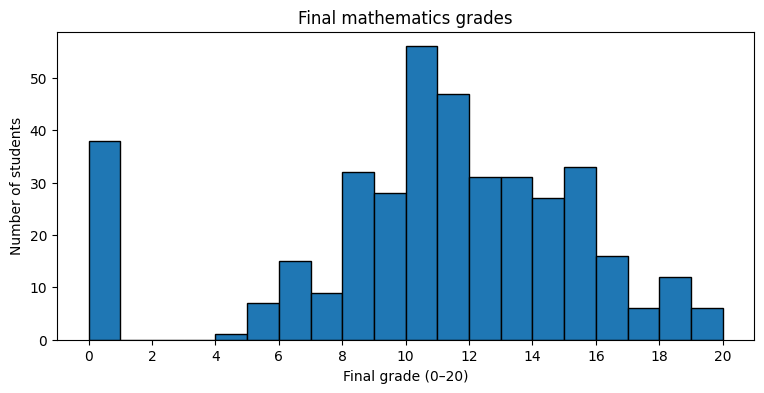

In [3]:
# See how the final grades are distributed.
plt.figure(figsize=(9, 4))
plt.hist(students["G3"], bins=20, edgecolor="black")
plt.title("Final mathematics grades")
plt.xlabel("Final grade (0–20)")
plt.ylabel("Number of students")
plt.xticks(range(0, 21, 2))
plt.show()

array([[<Axes: title={'center': 'final_grade_zero_to_onehundred'}>]],
      dtype=object)

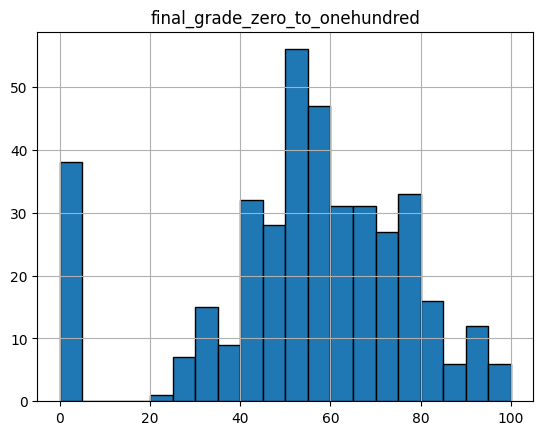

In [4]:
students["final_grade_zero_to_onehundred"] = students["G3"] * 5
students.hist(column="final_grade_zero_to_onehundred",bins=20, edgecolor="black")

## 4. Choose Features [link](https://archive.ics.uci.edu/dataset/320/student+performance) to data dictionary and meaning of every column.

We'll keep it simple with **7 numeric columns**:

| Column | Meaning |
|---|---|
| `G1` | First grading-period grade (0–20) |
| `G2` | Second grading-period grade (0–20) |
| `studytime` | Weekly study time (1 = least, 4 = most) |
| `failures` | Number of past class failures |
| `absences` | Number of school absences |
| `goout` | Frequency of going out with friends (1–5) |
| `freetime` | Amount of free time after school (1–5) |

We use `G1` and `G2` because they are available **before** the final grade. If we wanted to predict **at the start of the year**, we would need to remove them.

### All columns and information here. 

In [5]:
students.head().T

,0,1,2,3,4
school,GP,GP,GP,GP,GP
sex,F,F,F,F,F
age,18,17,15,15,16
address,U,U,U,U,U
famsize,GT3,GT3,LE3,GT3,GT3
Pstatus,A,T,T,T,T
Medu,4,1,1,4,3
Fedu,4,1,1,2,3
Mjob,at_home,at_home,at_home,health,other
Fjob,teacher,other,other,services,other


In [7]:
students.school.value_counts()

school
GP    349
MS     46
Name: count, dtype: int64

In [8]:
students.columns

Index(['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu',
       'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime',
       'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery',
       'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc',
       'Walc', 'health', 'absences', 'G1', 'G2', 'G3'],
      dtype='str')

In [8]:


# X = information we use to make predictions.
features = ["G1", "G2", "studytime", "failures", "absences", "goout", "freetime"]
# features = ["studytime", "failures", "absences", "goout", "freetime"]

X = students[features]

# y = the correct answer we want to predict.
y = students["G3"]

# Check for missing values before training.
print("Missing values per feature:")
print(X.isna().sum())

X.head()

Missing values per feature:
G1           0
G2           0
studytime    0
failures     0
absences     0
goout        0
freetime     0
dtype: int64


,G1,G2,studytime,failures,absences,goout,freetime
0,5,6,2,0,6,4,3
1,5,5,2,0,4,3,3
2,7,8,2,3,10,2,3
3,15,14,3,0,2,2,2
4,6,10,2,0,4,2,3


## 5. Split students into training and test sets

- **80% training:** Our model learns from these students.
- **20% testing:** Students the model hasn't seen while learning.

`random_state=42` makes the split repeatable, so everyone in class gets the same result.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 316
Testing students: 79


## 6. Train our decision tree regressor

A **regression tree** predicts a *number*. Each split asks a yes/no question about one feature.

`max_depth=3` keeps the tree small enough to draw and explain.

In [10]:
# Make a small tree with at most 3 levels of questions.
tree = DecisionTreeRegressor(max_depth=3, random_state=42)

# The model learns only from the training students.
tree.fit(X_train, y_train)

# Predict final grades for unseen students.
tree_predictions = tree.predict(X_test)

# Look at some real grades vs. predicted grades.
comparison = pd.DataFrame({
    "Actual grade": y_test.to_numpy(),
    "Predicted grade": np.round(tree_predictions, 1)
})
comparison.head(10)

,Actual grade,Predicted grade
0,10,9.4
1,12,11.5
2,5,6.6
3,10,9.4
4,9,9.4
5,13,13.0
6,18,18.3
7,6,6.6
8,0,6.5
9,14,13.0


## 7. Draw the whole tree

**How to read it:**
- Start at the **top** node.
- If the condition is **True**, go **left**; otherwise go **right**.
- `samples` = number of *training* students in that node.
- `value` = average final grade of those training students. That's the prediction at a leaf!

The tree below has at most **3 splits from root to leaf**.

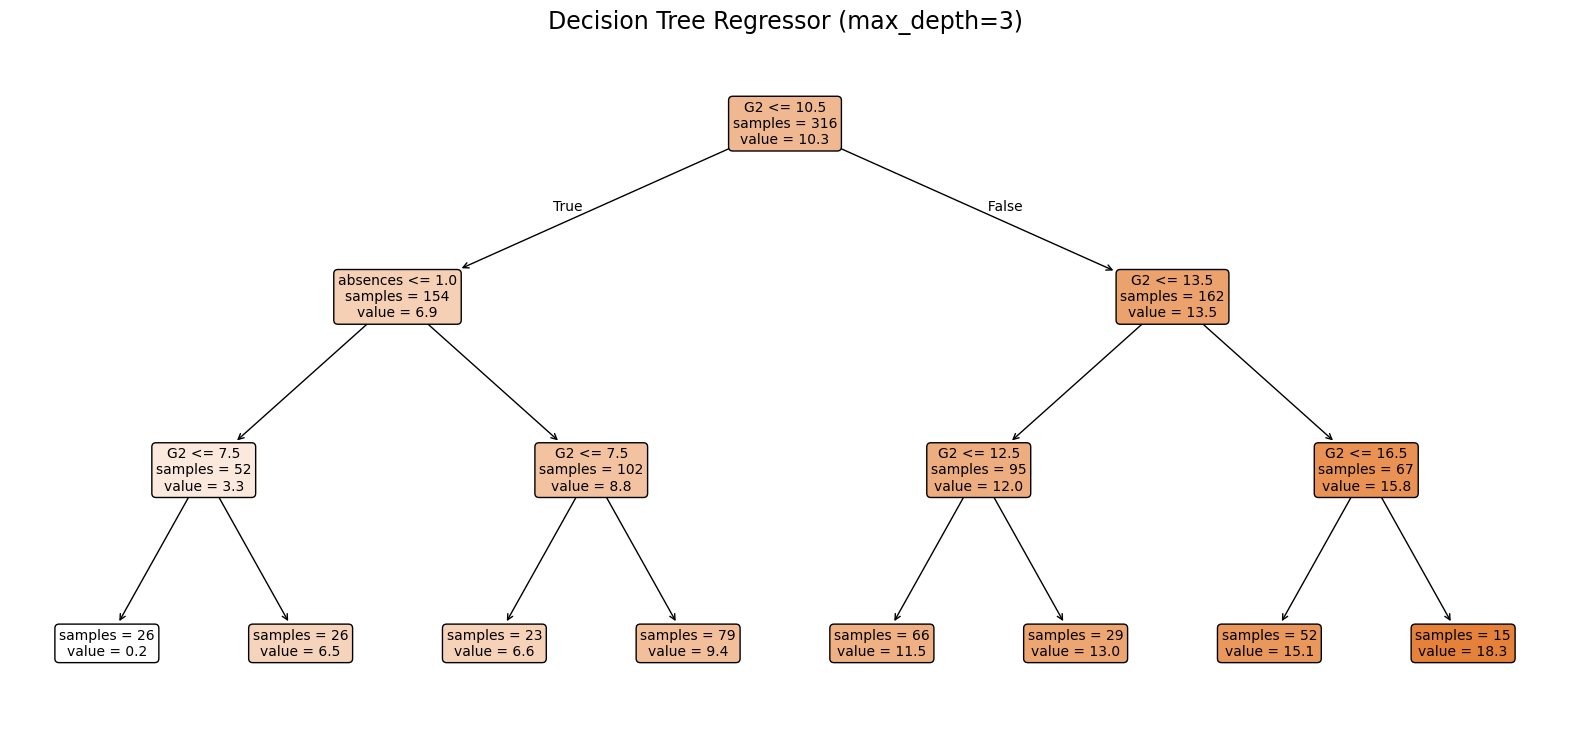

In [11]:
plt.figure(figsize=(20, 9))

plot_tree(
    tree,
    feature_names=features,
    filled=True,
    rounded=True,
    impurity=False,  # Hide the MSE formula to keep labels clean.
    precision=1,
    fontsize=10
)

plt.title("Decision Tree Regressor (max_depth=3)", fontsize=17)
plt.show()

## 8. Evaluate the predictions

We use **regression metrics**, because our output is a number.

- **MAE (mean absolute error):** On average, how many grade points are we off? **Lower is better.**
- **RMSE (root mean squared error):** Similar, but it penalizes big misses more. **Lower is better.**
- **R²:** How much better are we than always predicting the average grade? **1 is perfect; 0 is roughly equal to the average-grade baseline; negative is worse.**

Let's compare our tree with a very simple baseline that always predicts the average *training* grade.

In [12]:
# Baseline: always predict the average training grade.
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

# How wrong is our simple baseline?
baseline_mae = mean_absolute_error(y_test, baseline_predictions)

# How wrong is our decision tree?
tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(mean_squared_error(y_test, tree_predictions))
tree_r2 = r2_score(y_test, tree_predictions)

print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")

Baseline MAE: 3.65 grade points
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77


### Actual grade vs. predicted grade

If predictions were perfect, every dot would lie on the dashed diagonal line. Dots farther away mean bigger errors.

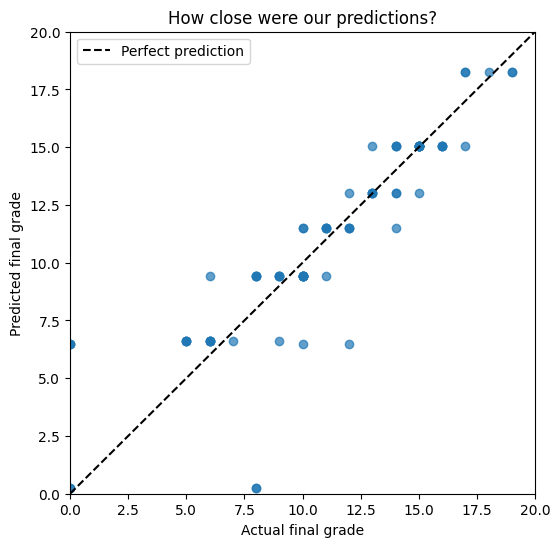

In [13]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, tree_predictions, alpha=0.7)
plt.plot([0, 20], [0, 20], "k--", label="Perfect prediction")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Actual final grade")
plt.ylabel("Predicted final grade")
plt.title("How close were our predictions?")
plt.legend()
plt.show()

## 9. Which features mattered most?

**Feature importance** measures how much each feature helped the tree reduce prediction error in its *training data*.

These scores add up to **1.0**. A high score means the tree used that feature to make useful splits. **It does not prove causation.**

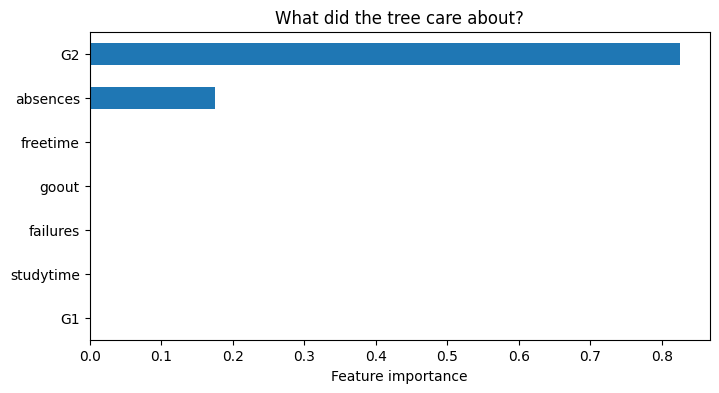

G2           0.825
absences     0.175
G1           0.000
studytime    0.000
failures     0.000
goout        0.000
freetime     0.000
dtype: float64


In [14]:
# Pair every feature name with its importance score.
importance = pd.Series(tree.feature_importances_, index=features)

# Put the largest importance at the top of the chart.
importance = importance.sort_values()

plt.figure(figsize=(8, 4))
importance.plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("What did the tree care about?")
plt.show()

print(importance.sort_values(ascending=False).round(3))

## 10. Bonus: try a Random Forest Regressor

A **random forest** averages predictions from many different decision trees. It is often more accurate than one tiny tree, but harder to draw.

We'll try **100 trees** and compare the errors on the *same test students*.

In [21]:
# A forest of 100 trees, rather than one tree of depth 3.
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

# How wrong is our decision tree?
print(f"Baseline MAE: {baseline_mae:.2f} grade points")
print('/'*33)
print(f"Tree MAE:     {tree_mae:.2f} grade points")
print(f"Tree RMSE:    {tree_rmse:.2f} grade points")
print(f"Tree R²:      {tree_r2:.2f}")


print('/'*33)
print(f"Random forest MAE:  {forest_mae:.2f}")
print(f"Random forest RMSE: {forest_rmse:.2f}")
print(f"Random forest R²:   {forest_r2:.2f}")

Baseline MAE: 3.65 grade points
/////////////////////////////////
Tree MAE:     1.31 grade points
Tree RMSE:    2.17 grade points
Tree R²:      0.77
/////////////////////////////////
Random forest MAE:  1.13
Random forest RMSE: 1.71
Random forest R²:   0.86


## 11. Confusion matrix: a **different** problem (Pass vs. Fail)

A confusion matrix cannot directly evaluate predictions like **12.7/20**. It needs **categories**.

So let's create a **separate decision tree classifier**, also with `max_depth=3`:

- **Fail (0):** Final grade below 10.
- **Pass (1):** Final grade 10 or higher.

We use the *same features and the same train/test split*, but now train the model to predict **Pass or Fail**, not an exact grade.

---

# Okay.  So G2 is by far the most important factor to determining G3.  But thats obvious....  Tell me something more interesting. 
### Remove G1 and G2, and try using interesting features like "Walc" weekend alcohol consumption. "
### Full list of features [see the data dict](https://archive.ics.uci.edu/dataset/320/student+performance)

# Student that comes up with the MOST INTERESTING finding gets a FULL WEEK homework pass and letter of rec from me. 
Some interesting features:
* "absences" - number of school absences (numeric: from 0 to 93)
* "Walc" - weekend alcohol consumption (numeric: from 1 - very low to 5 - very high)
* "goout" - going out with friends (numeric: from 1 - very low to 5 - very high)
* "reason" - reason to choose this school (nominal: close to 'home', school 'reputation', 'course' preference or 'other')


In [24]:
features = students.drop(columns=["G1", "G2", "G3"]).columns.tolist()

X = pd.get_dummies(students[features], dtype=int)

y = students["G3"]


print("Missing values per feature:")
print(X.isna().sum())

X.head()

Missing values per feature:
age                  0
Medu                 0
Fedu                 0
traveltime           0
studytime            0
failures             0
famrel               0
freetime             0
goout                0
Dalc                 0
Walc                 0
health               0
absences             0
school_GP            0
school_MS            0
sex_F                0
sex_M                0
address_R            0
address_U            0
famsize_GT3          0
famsize_LE3          0
Pstatus_A            0
Pstatus_T            0
Mjob_at_home         0
Mjob_health          0
Mjob_other           0
Mjob_services        0
Mjob_teacher         0
Fjob_at_home         0
Fjob_health          0
Fjob_other           0
Fjob_services        0
Fjob_teacher         0
reason_course        0
reason_home          0
reason_other         0
reason_reputation    0
guardian_father      0
guardian_mother      0
guardian_other       0
schoolsup_no         0
schoolsup_yes        0
famsup

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,...,activities_no,activities_yes,nursery_no,nursery_yes,higher_no,higher_yes,internet_no,internet_yes,romantic_no,romantic_yes
0,18,4,4,2,2,0,4,3,4,1,...,1,0,0,1,0,1,1,0,1,0
1,17,1,1,1,2,0,5,3,3,1,...,1,0,1,0,0,1,0,1,1,0
2,15,1,1,1,2,3,4,3,2,2,...,1,0,0,1,0,1,0,1,1,0
3,15,4,2,1,3,0,3,2,2,1,...,0,1,0,1,0,1,0,1,0,1
4,16,3,3,1,2,0,4,3,2,1,...,1,0,0,1,0,1,1,0,1,0


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 316
Testing students: 79


In [26]:
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print(f"Random forest MAE:  {forest_mae:.2f}")
print(f"Random forest RMSE: {forest_rmse:.2f}")
print(f"Random forest R²:   {forest_r2:.2f}")

Random forest MAE:  3.01
Random forest RMSE: 3.77
Random forest R²:   0.31


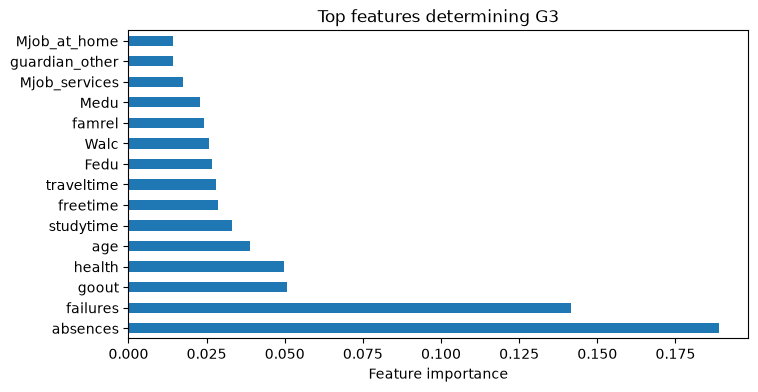

absences          0.189
failures          0.141
goout             0.051
health            0.050
age               0.039
studytime         0.033
freetime          0.029
traveltime        0.028
Fedu              0.027
Walc              0.026
famrel            0.024
Medu              0.023
Mjob_services     0.017
guardian_other    0.014
Mjob_at_home      0.014
dtype: float64


In [34]:
importance = pd.Series(forest.feature_importances_, index=X.columns)

importance = importance.sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importance.head(15).plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Top features determining G3")
plt.show()

print(importance.sort_values(ascending=False).round(3).head(15))

In [36]:
features = ["absences", "goout", "health", "age", "freetime", "traveltime", "Fedu", "Walc", "famrel", "Medu"]

X = pd.get_dummies(students[features], dtype=int)

y = students["G3"]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

In [ ]:
forest = RandomForestRegressor(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print(f"Random forest MAE:  {forest_mae:.2f}")
print(f"Random forest RMSE: {forest_rmse:.2f}")
print(f"Random forest R²:   {forest_r2:.2f}")

Random forest MAE:  3.57
Random forest RMSE: 4.45
Random forest R²:   0.03


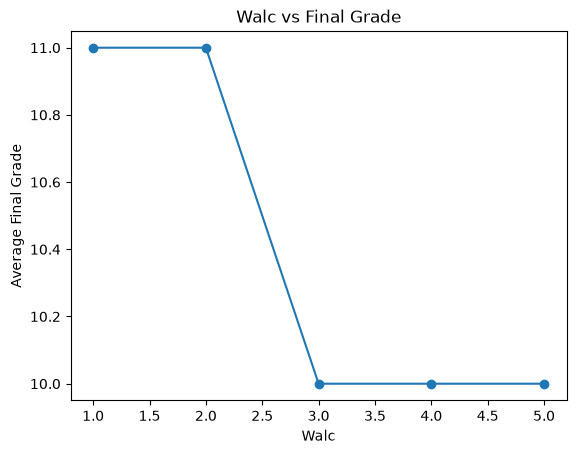

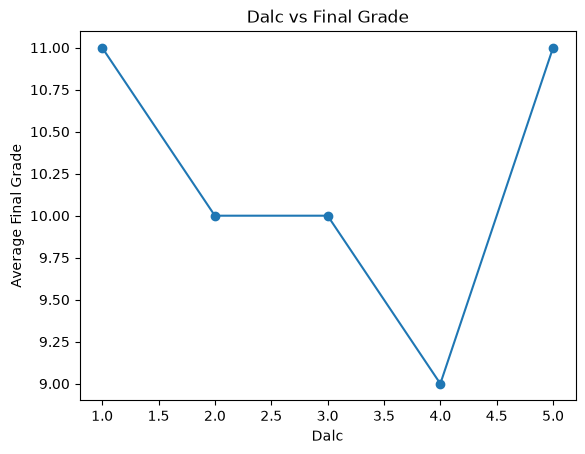

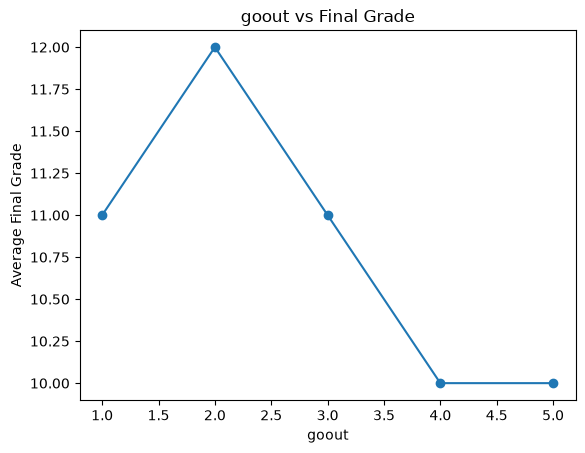

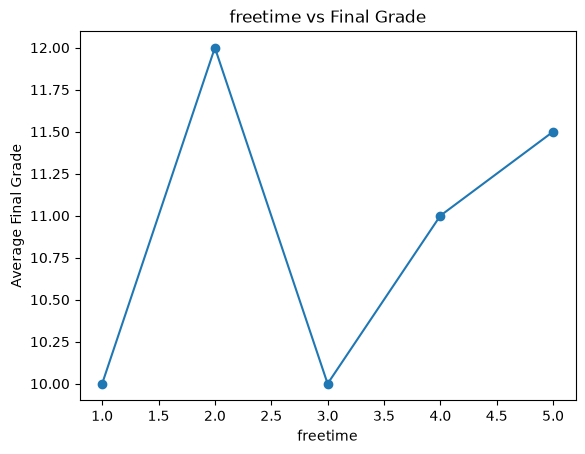

In [ ]:

for feature in features:
    students.groupby(feature)["G3"].median().plot(marker="o")

    plt.xlabel(feature)
    plt.ylabel("Average Final Grade")
    plt.title(f"{feature} vs Final Grade")
    plt.show()


---

In [27]:
students['above_avg'] = students['G3'] > students['G3'].mean()
students.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,above_avg
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,False
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,False
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,False
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,True
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,False


In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, f1_score
from sklearn.dummy import DummyClassifier

In [65]:
features = features = students.drop(columns=["G1", "G2", "G3", "above_avg"]).columns.tolist()

X = pd.get_dummies(students[features], dtype=int)
y = students["above_avg"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

forest = RandomForestClassifier(n_estimators=100, random_state=42)
forest.fit(X_train, y_train)
forest_predictions = forest.predict(X_test)


print(f"accuracy: {accuracy_score(y_test, forest_predictions):.2f}")
print(f"f1 score: {f1_score(y_test, forest_predictions):.2f}")

accuracy: 0.63
f1 score: 0.69


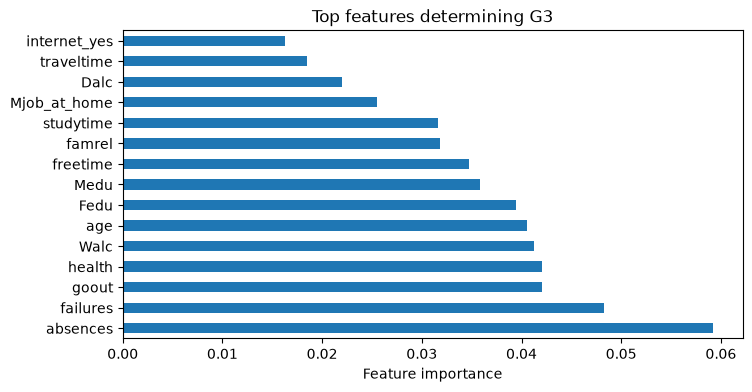

absences        0.059
failures        0.048
goout           0.042
health          0.042
Walc            0.041
age             0.041
Fedu            0.039
Medu            0.036
freetime        0.035
famrel          0.032
studytime       0.032
Mjob_at_home    0.025
Dalc            0.022
traveltime      0.018
internet_yes    0.016
dtype: float64


In [42]:
importance = pd.Series(forest.feature_importances_, index=X.columns)

importance = importance.sort_values(ascending=False)

plt.figure(figsize=(8, 4))
importance.head(15).plot(kind="barh")
plt.xlabel("Feature importance")
plt.title("Top features determining G3")
plt.show()

print(importance.sort_values(ascending=False).round(3).head(15))

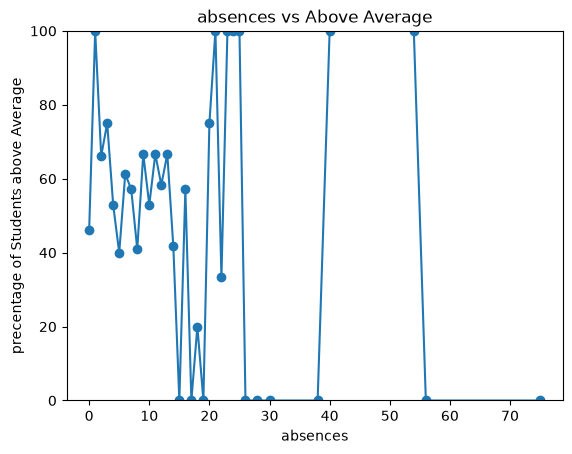

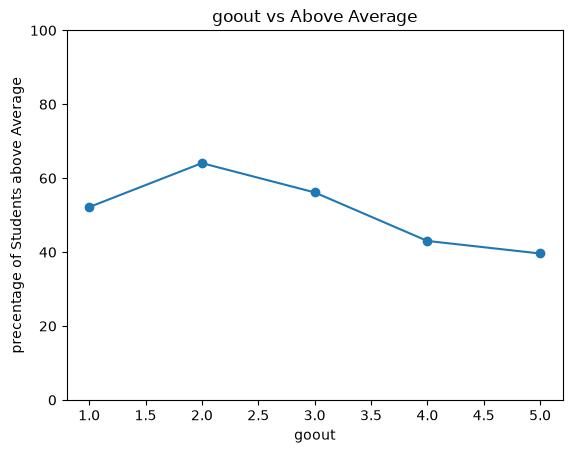

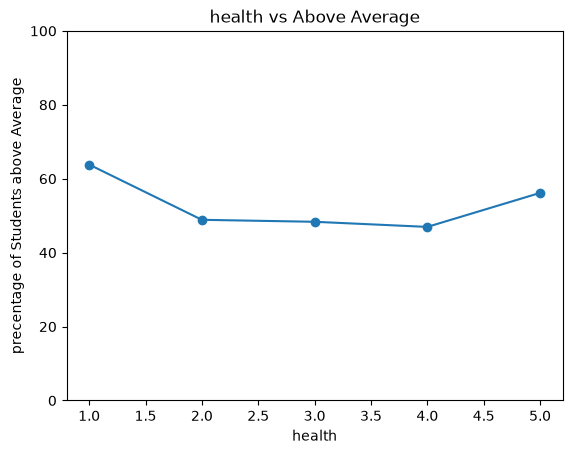

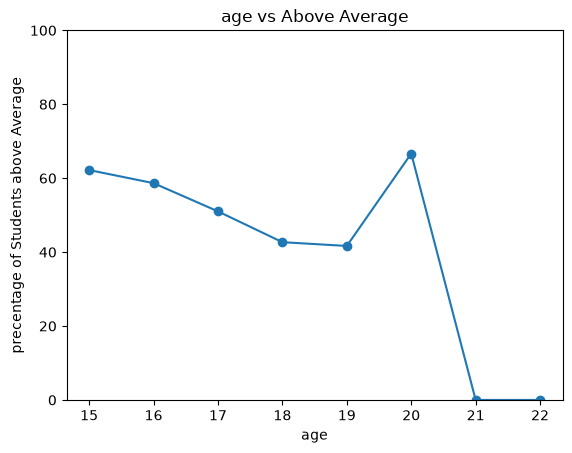

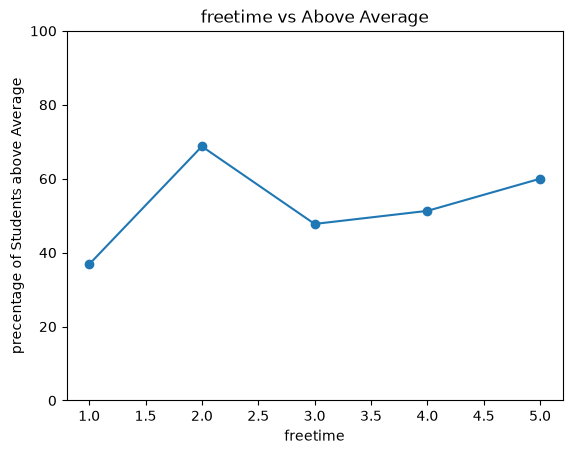

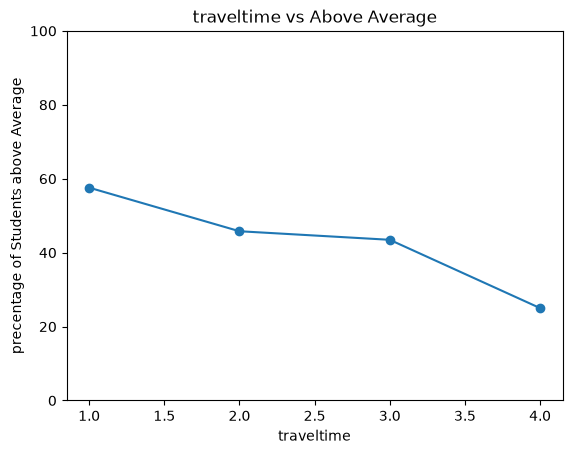

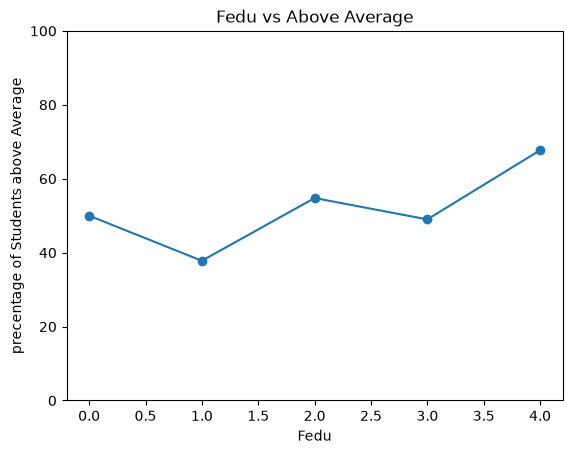

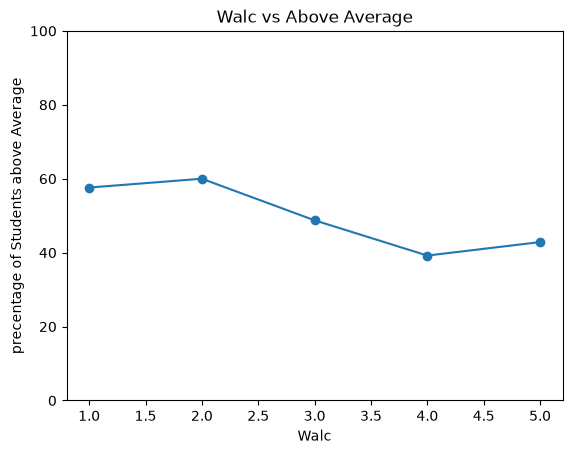

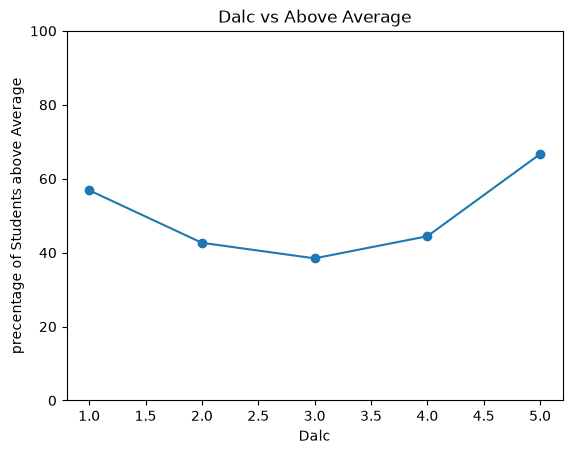

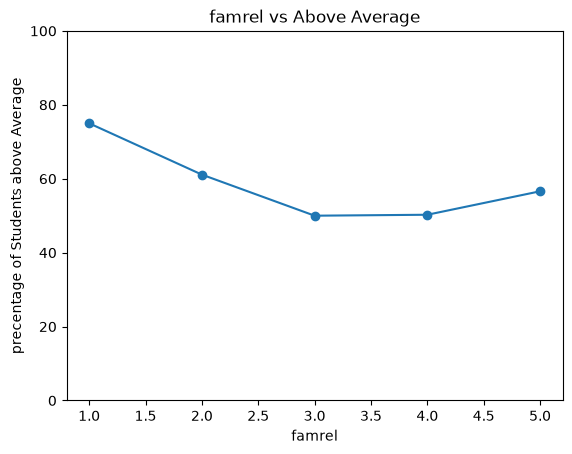

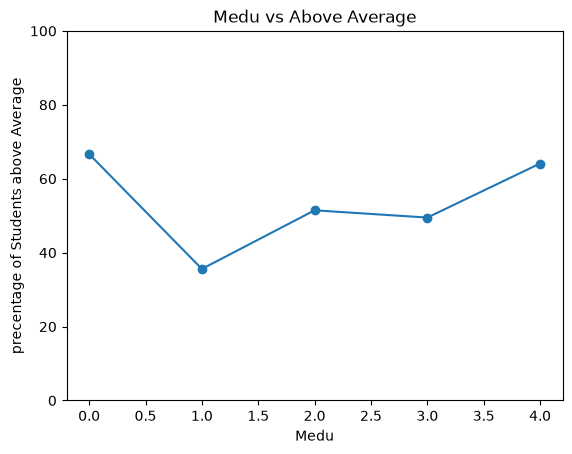

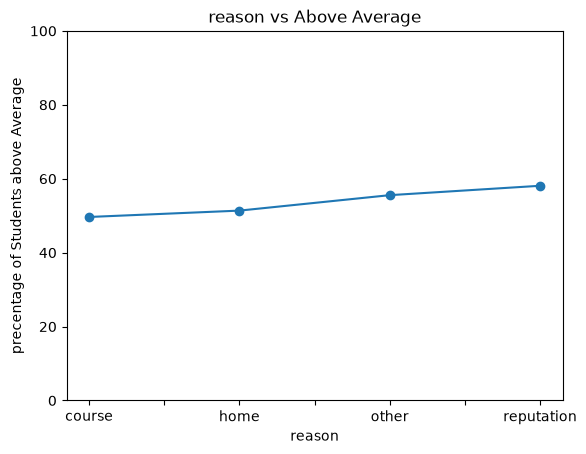

In [77]:
features = ["absences", "goout", "health", "age", "freetime", "traveltime", "Fedu", "Walc", "Dalc", "famrel", "Medu", 'reason']
for feature in features:
    students.groupby(feature)["above_avg"].mean().mul(100).plot(marker = 'o')

    plt.xlabel(feature)
    plt.ylabel('precentage of Students above Average')
    plt.title(f"{feature} vs Above Average")
    plt.ylim(0, 100)
    plt.show()

In [ ]:
# for only the graphs that gave us a clear pattern
# check the number of students @ each group
features = ["goout", "traveltime", "Walc", "famrel", "age"]

for feature in features:
    print(students.groupby(feature)["above_avg"].count())


goout
1     23
2    103
3    130
4     86
5     53
Name: above_avg, dtype: int64
traveltime
1    257
2    107
3     23
4      8
Name: above_avg, dtype: int64
Walc
1    151
2     85
3     80
4     51
5     28
Name: above_avg, dtype: int64
famrel
1      8
2     18
3     68
4    195
5    106
Name: above_avg, dtype: int64
age
15     82
16    104
17     98
18     82
19     24
20      3
21      1
22      1
Name: above_avg, dtype: int64


## Observations

Only 5 featurea showed interesting patterns (going out, travel time, weekend alcohol consumption, family relationships, and age)
- I excluded age and family relationships because some groups had very few students so the results are unreliable
- Travel time also had a small group of only 8 students so we need to be careful with it
- The reason for choosing the school was also interesting but the differences were too small to make a conclusion

--> going out and weekend alcohol consumption gave the most useful insights

In [90]:
#Double check with p-values
from scipy.stats import spearmanr

features = ["goout", "Walc", "traveltime"]

for feature in features:
    r, p = spearmanr(students[feature], students["above_avg"])

    print(f"{feature}:")
    print(f" P-value: {p:.4f}")
    print()

goout:
 P-value: 0.0014

Walc:
 P-value: 0.0138

traveltime:
 P-value: 0.0082



In [92]:

# check if there is another significant feature that wwe missed 
features = ["absences", "health", "age", "freetime", "Fedu", "Dalc", "famrel", "Medu"]

for feature in features:
    r, p = spearmanr(students[feature], students["above_avg"])

    print(f"{feature}:")
    print(f" P-value: {p:.4f}")

absences:
 P-value: 0.8564
health:
 P-value: 0.9225
age:
 P-value: 0.0025
freetime:
 P-value: 0.7799
Fedu:
 P-value: 0.0006
Dalc:
 P-value: 0.0234
famrel:
 P-value: 0.8039
Medu:
 P-value: 0.0009


In [96]:
features = ["goout", "Walc", "traveltime", "Fedu" , "Medu",  "Dalc"]  # statistically significant

for feature in features:
    r, p = spearmanr(students[feature], students["above_avg"])

    print(f"{feature}:")
    print(f" Correlation: {r:.3f}")
    print(f" P-value: {p:.4f}")

goout:
 Correlation: -0.160
 P-value: 0.0014
Walc:
 Correlation: -0.124
 P-value: 0.0138
traveltime:
 Correlation: -0.133
 P-value: 0.0082
Fedu:
 Correlation: 0.171
 P-value: 0.0006
Medu:
 Correlation: 0.167
 P-value: 0.0009
Dalc:
 Correlation: -0.114
 P-value: 0.0234




## Conclusion
- Students whose Parents (father/mother) have higher education levels are more likely to score above average
- Students who go out more frequently are less likely to score above average
- Students who drink more alcohol on (weekends/weekdays) are less likely to score above average
- Students with longer travel times tend to be less likely to score above average

The interesting part is that Parents' education has stronger correlations with students scoring above average compared to their social habits. but all the relationships are still weak.